# Laboratório do Image Classifier
#### Aluno : João Maria de Araujo Nogueira Junior

Neste laboratorio estarei apresentando um classificador de imagens em rede densa.

## Primeiro Passo
Primeiramente importei as bibliotecas e defini alguns hyperparametros da rede como tamanho de batch, numero de epocas e learning rate

In [67]:

import os
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
import random
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import ConfusionMatrixDisplay

from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

dataset_dir = "imgs"

batch_size = 16
num_epochs = 10
lr = 1e-3


## importação
Nesse módulo, importei as imagens e designei á cada uma, sua classe, utilizando o nome de sua pasta de origem como rótulo.

In [54]:

images = []
labels = []

for label in sorted(os.listdir(dataset_dir)):
    folder = os.path.join(dataset_dir, label)

    if not os.path.isdir(folder) or label.startswith("."):
        continue

    for img in os.listdir(folder):
        if img.lower().endswith((".jpg", ".jpeg", ".png", ".webp")):
            images.append(os.path.join(folder, img))
            labels.append(label)

classes = sorted(set(labels))
class_to_idx = {name: i for i, name in enumerate(classes)}

labels = [class_to_idx[label] for label in labels]

num_classes = len(classes)

print(class_to_idx)
print(f"Total de imagens: {len(images)}")


{'arvores': 0, 'cogumelos': 1, 'insetos': 2, 'magos': 3}
Total de imagens: 105


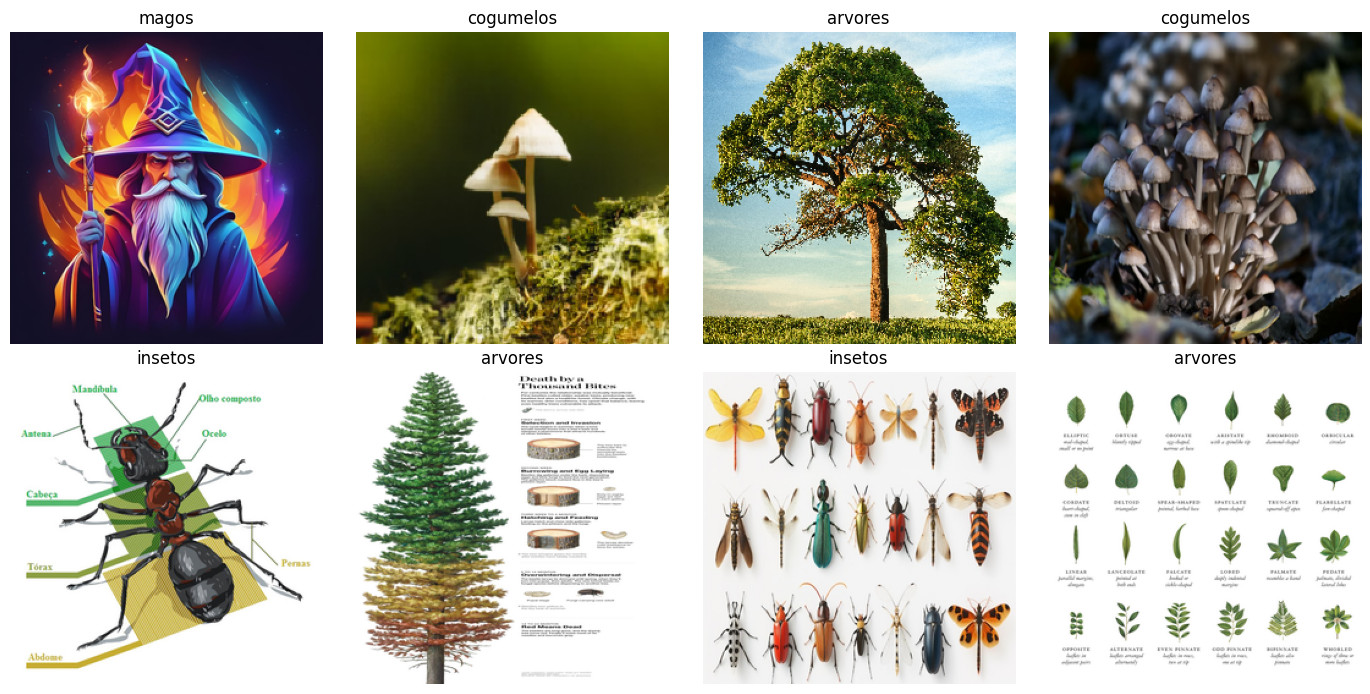

In [55]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))

for ax in axes.flat:
    idx = random.randrange(len(images))

    image = Image.open(images[idx]).convert("RGB")

    ax.imshow(image)
    ax.set_title(classes[labels[idx]])
    ax.axis("off")

plt.tight_layout()
plt.show()

## Divisão de Treinamento e Validação
Realizei a divisão de 70/30 das imagens rotuladas para treinamento e validação do modelo.

In [56]:

X_train, X_temp, y_train, y_temp = train_test_split(images,labels,
    test_size=0.30,
    stratify=labels,
    random_state=42
)

X_val, X_test, y_val, y_test = train_test_split(X_temp,y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=42
)

print(f"Treino: {len(X_train)}")
print(f"Validação: {len(X_val)}")
print(f"Teste: {len(X_test)}")


Treino: 73
Validação: 16
Teste: 16


## Normalização e Data Augmentation

Antes de realizar qualquer tipo de transformação nas imagens precisei normaliza-las e re-escalona-las para os padrões do ImageNet, sendo esse,o banco de dados, ao qual os modelos que estarei utilizando e aplicando um fine-tunning (feature extraction), foram treinados sobre.

Abaixo, defini algumas das transformações que estarei fazendo nos dominios de treino e de validação.

In [57]:
#Padrões de Normalização do Imagenet
mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.3,contrast=0.4,saturation=0.3),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)])


eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)])


### Visualização do Data Augmentation

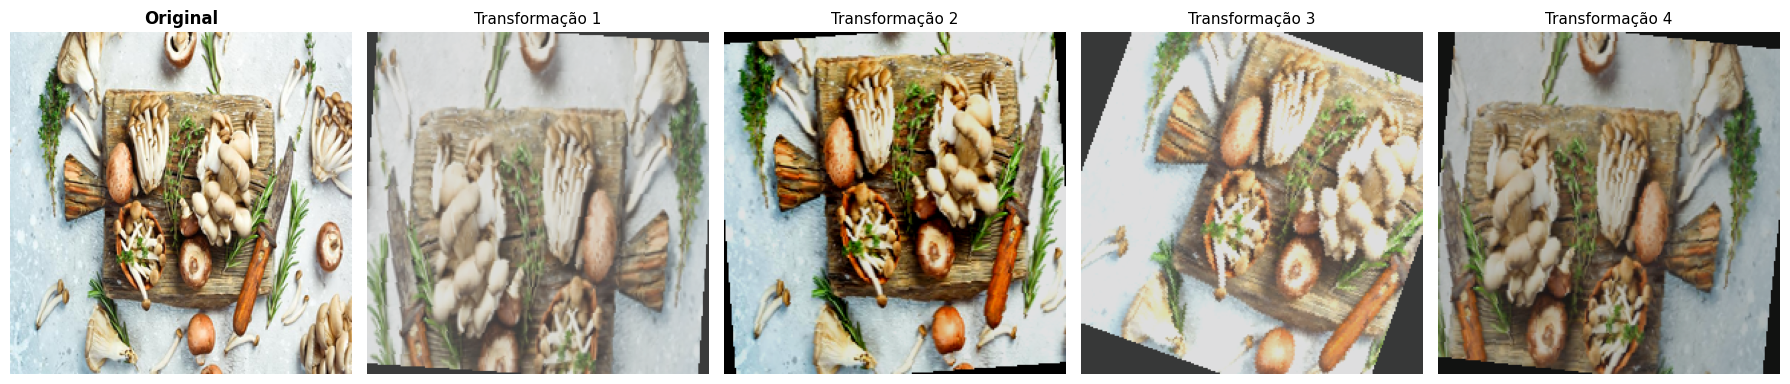

In [70]:

#escolha aleatoria de imagem
raw_sample_img = Image.open(X_train[0]).convert("RGB")

fig, axes = plt.subplots(1, 5, figsize=(18, 4))

#original
axes[0].imshow(raw_sample_img)
axes[0].set_title("Original", fontsize=12, fontweight='bold')
axes[0].axis("off")

mean_arr = np.array(mean)
std_arr = np.array(std)
#aplica transformações
for i in range(1, 5):
    augmented_tensor = train_transform(raw_sample_img)

    img_np = augmented_tensor.cpu().clone().detach().numpy().transpose((1, 2, 0))
    img_np = std_arr * img_np + mean_arr
    augmented_img = np.clip(img_np, 0, 1)

    axes[i].imshow(augmented_img)
    axes[i].set_title(f"Transformação {i}", fontsize=11)
    axes[i].axis("off")

plt.tight_layout()
plt.show()

Neste modulo criei a classe ImageDataset que vai armazenar os caminhos das imagens, rotulos e transforms aplicados.

In [58]:

class ImageDataset(Dataset): #classe que indexa as imagens
    def __init__(self, images, labels, transform=None):
        self.images = images
        self.labels = labels
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = Image.open(self.images[idx]).convert("RGB")
        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label


train_set = ImageDataset(X_train, y_train, train_transform)
val_set = ImageDataset(X_val, y_val, eval_transform)
test_set = ImageDataset(X_test, y_test, eval_transform)


## Definição de DataLoaders
 os DataLoaders que serão responsáveis por agrupar as imagens nos batches e por randomizar os dados treinamento são definidos, abaixo:

In [59]:
train_dataloader = DataLoader(train_set,batch_size=batch_size,shuffle=True)

val_dataloader = DataLoader(val_set,batch_size=batch_size,shuffle=False)

test_dataloader = DataLoader(test_set,batch_size=batch_size,shuffle=False)

print(f"batches de treino: {len(train_dataloader)}")
print(f"batches de validação: {len(val_dataloader)}")
print(f"batchs de teste: {len(test_dataloader)}")

batches de treino: 5
batches de validação: 1
batchs de teste: 1


#Import do Resnet
Pra fazer o fine-tunning resolvi importar o ResNet18 já que é um modelo residual que tem um desempenho superior ao Alexnet e menor quantidade parametros.

In [60]:
weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights)

# congela todos os parametros do modelo
model.requires_grad_(False)

# mudança da cabeça de classificação
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, num_classes)

model = model.to(device)
print(model.fc)

Linear(in_features=512, out_features=4, bias=True)


#Treinamento e Validação

In [61]:
criterion = nn.CrossEntropyLoss()

def evaluate(model, dataloader):
    model.eval()

    total_loss = 0
    correct = 0

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            labels = labels.to(device)

            logits = model(images)
            loss = criterion(logits, labels)

            total_loss += loss.item() * len(images)
            correct += (logits.argmax(1) == labels).sum().item()

    n = len(dataloader.dataset)
    return total_loss / n, correct / n


In [62]:

def train(model, train_dataloader, val_dataloader, num_epochs, lr=1e-4):
    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    optimizer = torch.optim.Adam(model.fc.parameters(), lr=lr)

    for epoch in range(num_epochs):
        model.train()
        total_loss = 0
        correct = 0

        for images, labels in train_dataloader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            logits = model(images)
            loss = criterion(logits, labels)

            loss.backward()
            optimizer.step()

            total_loss += loss.item() * len(images)
            correct += (logits.argmax(1) == labels).sum().item()

        n = len(train_dataloader.dataset)

        train_loss = total_loss / n
        train_acc = correct / n

        val_loss, val_acc = evaluate(model, val_dataloader)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)

        print(
            f"Época {epoch+1}/{num_epochs} | "
            f"Train Loss: {train_loss:.3f} | "
            f"Train Acc: {train_acc:.3f} | "
            f"Val Loss: {val_loss:.3f} | "
            f"Val Acc: {val_acc:.3f}"
        )

    return history


In [63]:

torch.manual_seed(42)
history = train(model,train_dataloader,val_dataloader,num_epochs,lr)


Época 1/10 | Train Loss: 1.525 | Train Acc: 0.288 | Val Loss: 1.236 | Val Acc: 0.438
Época 2/10 | Train Loss: 1.218 | Train Acc: 0.452 | Val Loss: 1.002 | Val Acc: 0.625
Época 3/10 | Train Loss: 1.030 | Train Acc: 0.658 | Val Loss: 0.870 | Val Acc: 0.688
Época 4/10 | Train Loss: 0.936 | Train Acc: 0.740 | Val Loss: 0.763 | Val Acc: 0.812
Época 5/10 | Train Loss: 0.740 | Train Acc: 0.836 | Val Loss: 0.724 | Val Acc: 0.750
Época 6/10 | Train Loss: 0.668 | Train Acc: 0.863 | Val Loss: 0.629 | Val Acc: 0.812
Época 7/10 | Train Loss: 0.608 | Train Acc: 0.890 | Val Loss: 0.591 | Val Acc: 0.812
Época 8/10 | Train Loss: 0.574 | Train Acc: 0.836 | Val Loss: 0.524 | Val Acc: 0.938
Época 9/10 | Train Loss: 0.574 | Train Acc: 0.877 | Val Loss: 0.518 | Val Acc: 0.875
Época 10/10 | Train Loss: 0.462 | Train Acc: 0.918 | Val Loss: 0.543 | Val Acc: 0.875


## Visualização do desempenho


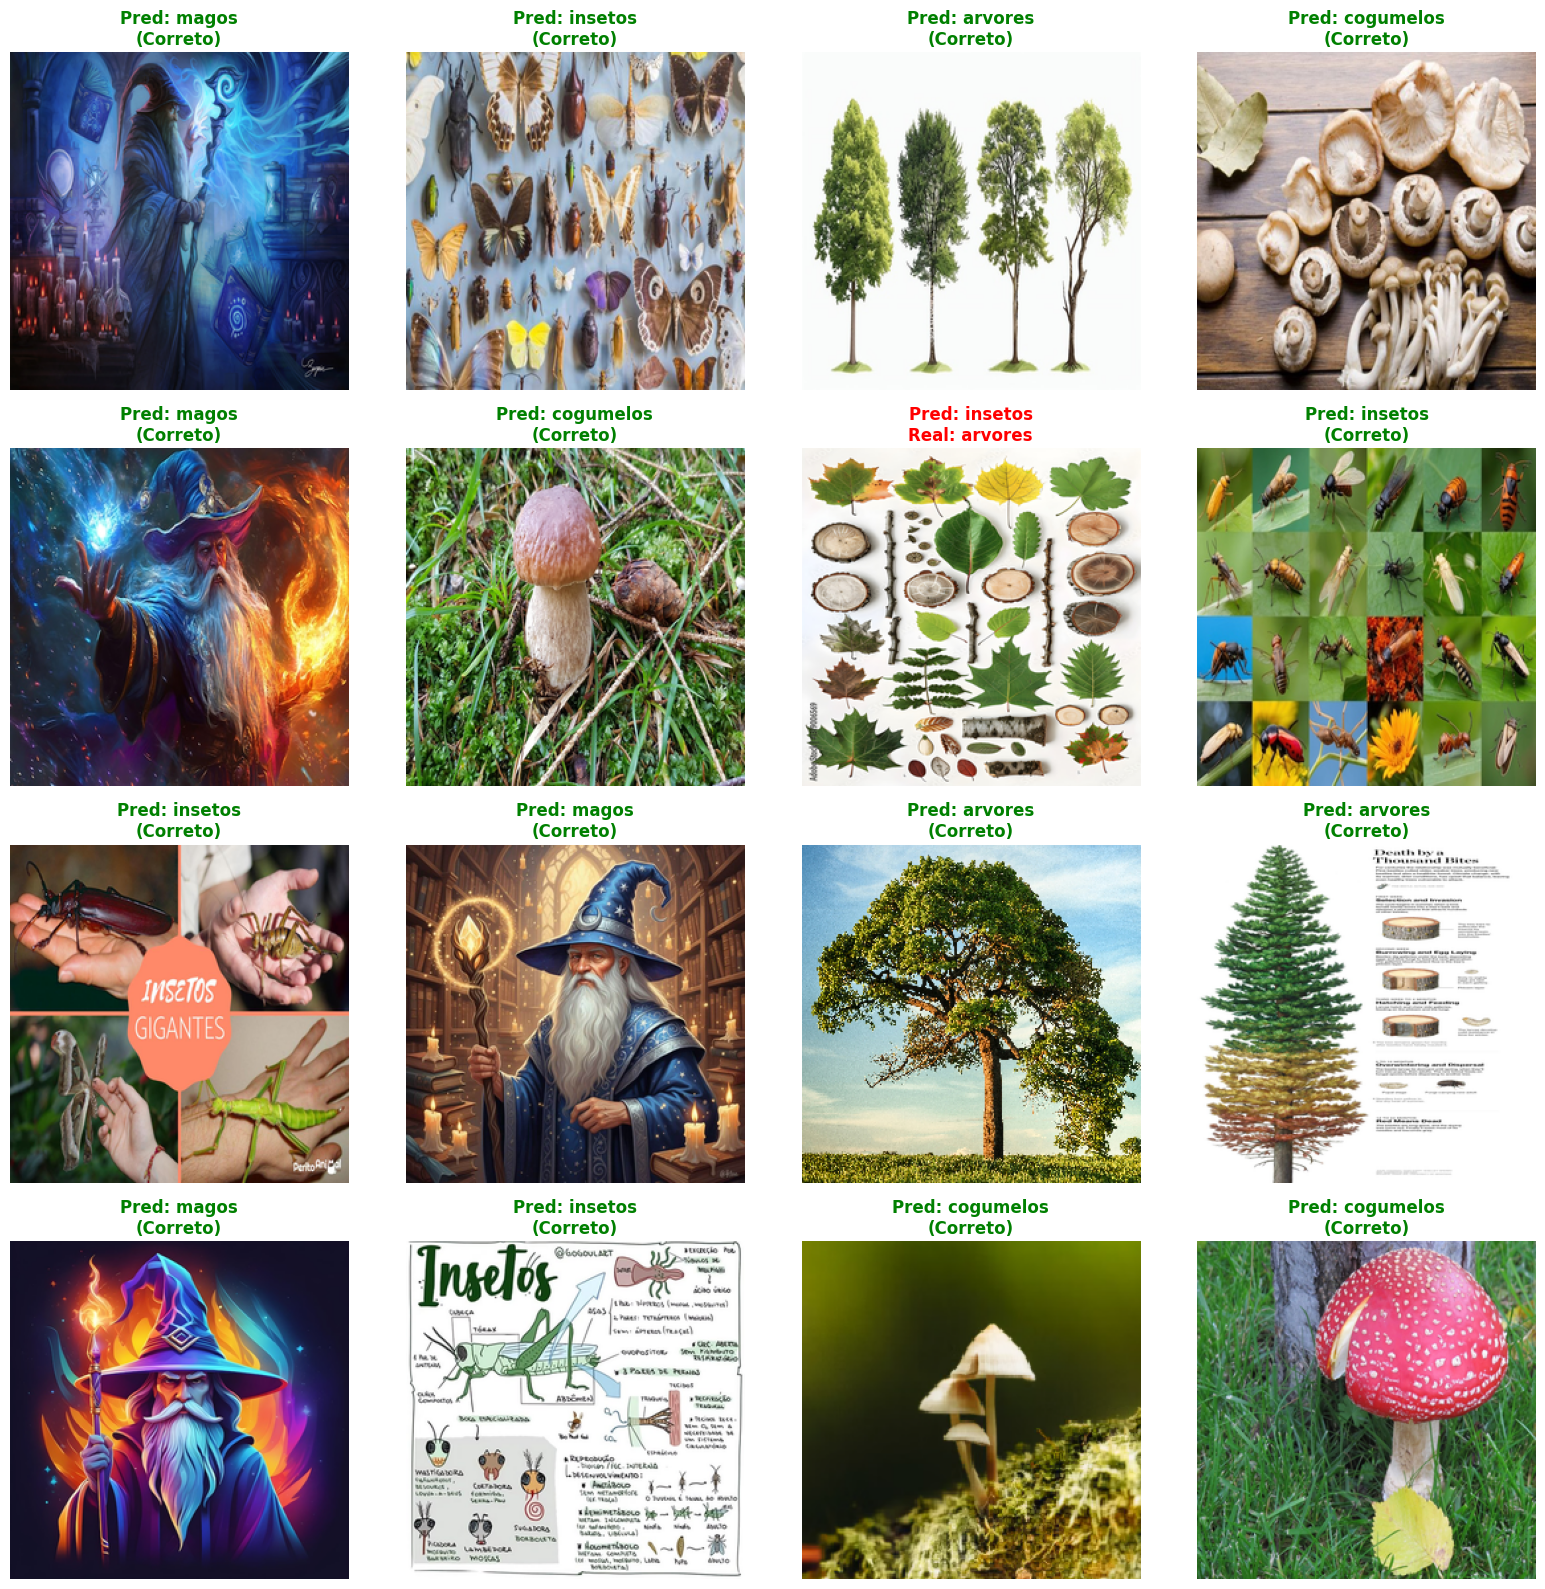

In [64]:
model.eval()

fig, axes = plt.subplots(4, 4, figsize=(16, 16))

with torch.no_grad():
    for i, ax in enumerate(axes.flat):
        if i >= len(test_set):
            ax.axis('off')
            continue

        #obtem imagem e label originais
        img_path = test_set.images[i]
        true_label_idx = test_set.labels[i]
        true_label_name = classes[true_label_idx]

        raw_image = Image.open(img_path).convert("RGB")
        input_tensor = eval_transform(raw_image).unsqueeze(0).to(device)

        outputs = model(input_tensor)
        pred_label_idx = outputs.argmax(1).item()
        pred_label_name = classes[pred_label_idx]

        if pred_label_idx == true_label_idx:
            title_color = 'green'
            title_text = f"Pred: {pred_label_name}\n(Correto)"
        else:
            title_color = 'red'
            title_text = f"Pred: {pred_label_name}\nReal: {true_label_name}"

        ax.imshow(raw_image)
        ax.set_title(title_text, color=title_color, fontsize=12, fontweight='bold')
        ax.axis('off')

plt.tight_layout()
plt.show()